# Olbrecht et al. 2021 — HGSOC
## 04 · EMT-TF expression (unconditional readout)

The EMT-TF step is **unconditional** — the final notebook regardless of the gate chain (here #04,
since Gate 3 is NA). Score a **widened** EMT-TF panel gated on **detectable expression** (eval lesson:
include FOXC / PRRX families, not only Snail/Zeb/Twist; VIM excluded — a marker, not a TF), pick the
most root- and most terminus-trending detectable factors, and overlay thresholded expressers on the
grey manifold (categorical, house `(3.5,1.5)`).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# read the signatures manifold (raw expression + house linear layout + pseudotime)
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(), 2), '->', round(t.max(), 2))

cells: 3936 | pseudotime 0.0 -> 10.04


In [4]:
# widened EMT-TF panel gated on detectable expression.
# per-TF: detection frac, pseudotime trend (rho), enriched-end bias.
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2',
         'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]; rho, p = spearmanr(tn, x); me, ml = x[early].mean(), x[late].mean()
    bias = (ml - me)/(ml + me + 1e-9)                      # +1 pure terminus, -1 pure root
    rows.append((g, round((x > 0).mean(), 3), round(me, 3), round(ml, 3),
                 round(rho, 3), round(bias, 3)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_early', 'mean_late', 'rho_vs_t', 'end_bias'])
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
FLOOR = 0.03
ok = df[df.frac_expr > FLOOR].copy()
tf_lo = ok.sort_values('rho_vs_t').iloc[0]['TF']          # most root-trending detectable factor
tf_hi = ok.sort_values('rho_vs_t').iloc[-1]['TF']         # most terminus-trending detectable factor
def _end_label(g):
    b = float(ok.loc[ok.TF == g, 'end_bias'].iloc[0])
    return 'terminus' if b > 0.05 else ('root' if b < -0.05 else 'pan-tumor')
lab_lo, lab_hi = _end_label(tf_lo), _end_label(tf_hi)
print(f'\ndetectable factors (>{FLOOR:.0%}): {ok.TF.tolist()}')
print(f'derived pair: {tf_lo} ({lab_lo}) <-> {tf_hi} ({lab_hi})')
print('note: the classical EMT programme is weak here; FOXC1 marks the root end and ZEB1 the')
print('      terminus - a data-driven readout matching the Kurten FOXC-at-root pattern.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t  end_bias
 FOXC1      0.119       0.071      0.044    -0.055    -0.238
 PRRX1      0.055       0.017      0.012    -0.002    -0.151
  ZEB2      0.056       0.019      0.014    -0.001    -0.158
 SNAI2      0.061       0.018      0.017     0.001    -0.047
TWIST2      0.035       0.008      0.006     0.001    -0.144
 PRRX2      0.135       0.061      0.057     0.003    -0.036
TWIST1      0.103       0.077      0.067     0.005    -0.068
 SNAI1      0.047       0.015      0.021     0.037     0.163
  ZEB1      0.155       0.064      0.122     0.106     0.315

detectable factors (>3%): ['FOXC1', 'PRRX1', 'ZEB2', 'SNAI2', 'TWIST2', 'PRRX2', 'TWIST1', 'SNAI1', 'ZEB1']
derived pair: FOXC1 (root) <-> ZEB1 (terminus)
note: the classical EMT programme is weak here; FOXC1 marks the root end and ZEB1 the
      terminus - a data-driven readout matching the Kurten FOXC-at-root pattern.


overlay thresholds (top decile among expressers): {'FOXC1': 0.95, 'ZEB1': 0.94} | cells shown: {'FOXC1': 47, 'ZEB1': 61}
FOXC1: 11.9% expressing; 47 shown (top decile), mean pseudotime of shown = 0.48 (all = 0.47)
ZEB1: 15.5% expressing; 61 shown (top decile), mean pseudotime of shown = 0.57 (all = 0.47)
saved expression.pdf


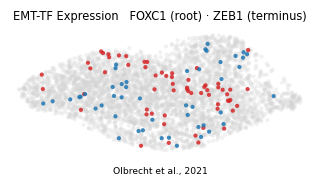

In [5]:
# deliverable: expression.pdf — categorical overlay of thresholded expressers on a grey
# manifold (house 3.5,1.5), NOT a continuous colormap. threshold = top decile among
# expressing cells, per factor, so a broadly-expressed TF is not washed across the manifold.
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_lo, tf_hi]:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_lo, tf_hi]}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(sel[g].sum()) for g in sel})
order = sorted([tf_lo, tf_hi], key=lambda g: -int(sel[g].sum()))
colors = {tf_lo: 'tab:blue', tf_hi: 'tab:red'}; labs = {tf_lo: lab_lo, tf_hi: lab_hi}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {tf_lo} ({labs[tf_lo]}) \u00b7 {tf_hi} ({labs[tf_hi]})', size=7.5)
ax.text(.5, -.14, 'Olbrecht et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in [tf_lo, tf_hi]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (top decile), '
          f'mean pseudotime of shown = {tn[sel[g]].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')